In [9]:
# File paths and tab-separated recall data
import csv
from pathlib import Path

# Data manipulation and numerical analysis
import numpy as np
import pandas as pd

# Visualization and notebook tables
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

## Load the NHTSA recall data

The supplied `RCL.txt` data dictionary (May 2025) specifies **29 fields**, in the order below. `FLAT_RCL_POST_2010.txt` is tab-delimited and has no header, so we supply these names when reading it.

Keep the official spelling `CONEQUENCE_DEFECT` to match the dictionary. Load values as strings to preserve leading zeros in identifiers such as `RCL_CMPT_ID` and `FMVSS`. Dates remain in `YYYYMMDD` format; `YEARTXT = 9999` means unknown or not applicable. Empty fields become missing values.

In [10]:
# Column names in the exact field order from RCL.txt.
RECALL_COLUMNS = [
    "RECORD_ID",          # Unique record sequence number
    "CAMPNO",             # NHTSA recall number
    "MAKETXT",            # Vehicle/equipment make
    "MODELTXT",           # Vehicle/equipment model
    "YEARTXT",            # Model year; 9999 = unknown or N/A
    "MFGCAMPNO",          # Manufacturer campaign number
    "COMPNAME",           # Component description
    "MFGNAME",            # Manufacturer that filed the Part 573 report
    "BGMAN",              # Manufacturing begin date
    "ENDMAN",             # Manufacturing end date
    "RCLTYPECD",          # Recall type: vehicle, equipment, child restraint, tire
    "POTAFF",             # Potential number of units affected
    "ODATE",              # Date manufacturer notified owners
    "INFLUENCED_BY",      # Recall initiator: MFR/OVSC/ODI
    "MFGTXT",             # Manufacturer of the recalled product
    "RCDATE",             # Date Part 573 report was received
    "DATEA",              # Record creation date
    "RPNO",               # Regulation part number
    "FMVSS",              # Federal Motor Vehicle Safety Standard number
    "DESC_DEFECT",        # Defect summary
    "CONEQUENCE_DEFECT",  # Consequence summary (official spelling)
    "CORRECTIVE_ACTION",  # Corrective summary
    "NOTES",              # Recall notes
    "RCL_CMPT_ID",        # Unique recalled component identifier
    "MFR_COMP_NAME",      # Manufacturer-supplied component name
    "MFR_COMP_DESC",      # Manufacturer-supplied component description
    "MFR_COMP_PTNO",      # Manufacturer-supplied component part number
    "DO_NOT_DRIVE",       # Consumer advisory: do not drive
    "PARK_OUTSIDE",       # Consumer advisory: park outside
]

In [11]:
# Support running Jupyter from either the repository root or notebooks/.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

recall_path = project_root / "data" / "raw" / "FLAT_RCL_POST_2010.txt"

recalls_df = pd.read_csv(
    recall_path,
    sep="\t",
    header=None,              # The first line is a record, not a header.
    names=RECALL_COLUMNS,
    dtype="string",          # Preserve identifiers and date text.
    quoting=csv.QUOTE_NONE,    # Quotes in recall narratives are literal text.
    encoding="utf-8",
    keep_default_na=False,    # Preserve literal strings such as "NA".
    na_values=[""],          # Only empty fields are treated as missing.
)

print(f"Loaded {len(recalls_df):,} records and {len(recalls_df.columns)} columns.")
# Transpose the preview so all 29 field names are easy to inspect.
display(recalls_df.head(3).T)

Loaded 247,149 records and 29 columns.


,0,1,2
RECORD_ID,81716,81717,81718
CAMPNO,10V525000,10V434000,10V434000
MAKETXT,ITASCA,NEWMAR,NEWMAR
MODELTXT,SUNRISE,KOUNTRY AIRE FW,CYPRESS FW
YEARTXT,2010,2008,2007
MFGCAMPNO,<NA>,<NA>,<NA>
COMPNAME,EQUIPMENT,EQUIPMENT,EQUIPMENT
MFGNAME,"WINNEBAGO INDUSTRIES, INC.",NEWMAR CORPORATION,NEWMAR CORPORATION
BGMAN,<NA>,20010816,20010816
ENDMAN,<NA>,20100602,20100602


# Dataset Overview

This analysis uses the NHTSA `FLAT_RCL_POST_2010.txt` recall extract. Rows contain campaign, vehicle/equipment, component, and recall narrative details; a campaign can appear in multiple rows, so the row count is not the number of distinct recalls. The supplied `RCL.txt` dictionary defines the 29 fields.

The tables below measure the current `recalls_df` without modifying its values or dtypes. They summarize the dataset's size and memory footprint, followed by a column inventory to guide later cleaning and analysis.

In [12]:
dataset_rows, dataset_columns = recalls_df.shape
dataset_memory_bytes = int(recalls_df.memory_usage(index=True, deep=True).sum())

dataset_overview = pd.DataFrame({
    "rows": [dataset_rows],
    "columns": [dataset_columns],
    "estimated_memory_MiB": [dataset_memory_bytes / 1024**2],
    "estimated_memory_GiB": [dataset_memory_bytes / 1024**3],
}, index=pd.Index(["recalls_df"], name="dataset"))

display(dataset_overview.style.format({
    "rows": "{:,.0f}",
    "columns": "{:,.0f}",
    "estimated_memory_MiB": "{:,.2f}",
    "estimated_memory_GiB": "{:.3f}",
}))

,rows,columns,estimated_memory_MiB,estimated_memory_GiB
dataset,,,,
recalls_df,"247,149",29,634.23,0.619


The shape shows the number of loaded records and fields. Memory is pandas' **deep estimate** for this DataFrame, including its index and string contents, expressed in MiB/GiB (powers of 1024). It is not the raw file size, total Python process memory, or peak processing memory; shared string storage can also affect this estimate. Copies, joins, temporary arrays, and embeddings can require additional memory, so this measurement alone does not establish that later operations will fit in RAM. Select only needed columns and use chunked processing when intermediate results would be large.

In [13]:
# Analytical roles based on RCL.txt; these labels do not cast any columns.
intended_column_types = {
    "RECORD_ID": "identifier",
    "CAMPNO": "identifier",
    "MAKETXT": "categorical",
    "MODELTXT": "categorical",
    "YEARTXT": "numeric",
    "MFGCAMPNO": "identifier",
    "COMPNAME": "categorical",
    "MFGNAME": "categorical",
    "BGMAN": "date",
    "ENDMAN": "date",
    "RCLTYPECD": "categorical",
    "POTAFF": "numeric",
    "ODATE": "date",
    "INFLUENCED_BY": "categorical",
    "MFGTXT": "categorical",
    "RCDATE": "date",
    "DATEA": "date",
    "RPNO": "identifier",
    "FMVSS": "identifier",
    "DESC_DEFECT": "free text",
    "CONEQUENCE_DEFECT": "free text",
    "CORRECTIVE_ACTION": "free text",
    "NOTES": "free text",
    "RCL_CMPT_ID": "identifier",
    "MFR_COMP_NAME": "free text",
    "MFR_COMP_DESC": "free text",
    "MFR_COMP_PTNO": "identifier",
    "DO_NOT_DRIVE": "categorical",
    "PARK_OUTSIDE": "categorical",
}

column_inventory = pd.DataFrame({
    "loaded_dtype": recalls_df.dtypes.astype(str),
    "non_null_count": recalls_df.count(),
    "nunique": recalls_df.nunique(dropna=True),
    "intended_type": pd.Series(intended_column_types),
}, index=recalls_df.columns).rename_axis("column")

display(column_inventory.style.format({
    "non_null_count": "{:,.0f}",
    "nunique": "{:,.0f}",
}))

,loaded_dtype,non_null_count,nunique,intended_type
column,,,,
RECORD_ID,string,"247,149","247,149",identifier
CAMPNO,string,"247,149","15,379",identifier
MAKETXT,string,"247,149","1,792",categorical
MODELTXT,string,"247,149","9,417",categorical
YEARTXT,string,"247,149",57,numeric
MFGCAMPNO,string,"182,253","9,788",identifier
COMPNAME,string,"247,149",633,categorical
MFGNAME,string,"247,149","1,947",categorical
BGMAN,string,"83,369","5,613",date


The inventory reports each column's actual loaded dtype, number of non-null values, and distinct non-null values (`nunique`), alongside its intended analytical role. All columns were loaded as pandas `string` values to preserve the source representation. In future implementations, datatypes should be converted for proper usage. Numeric-looking codes such as `RECORD_ID`, `RPNO`, and `FMVSS` are identifiers; `YEARTXT` is a discrete numeric model year, while the five date fields represent dates in `YYYYMMDD` format. Manufacturer-supplied component names/descriptions are treated as free text.

These counts describe stored values, not their validity: placeholders such as `YEARTXT = 9999` and literal `N/A` still count as non-null and distinct. Categorical labels are not proof of a validated set of categories. Intended types are planning labels only; dates and numeric fields still require validation and sentinel handling before conversion, and `recalls_df` remains unchanged.

# Keys and Duplicate Records

In [14]:
# Treat whitespace-only campaign numbers as missing.
campno = recalls_df["CAMPNO"].str.strip().replace("", pd.NA)

display(pd.Series({
    "Unique CAMPNO values": campno.nunique(),
    "Rows with missing CAMPNO": campno.isna().sum(),
    "Total rows": len(recalls_df),
}, name="Count").to_frame())

,Count
Unique CAMPNO values,15379
Rows with missing CAMPNO,0
Total rows,247149


## Duplicate-record checks

These checks leave `recalls_df` unchanged. Matching NA values are treated as equal when detecting duplicates. Duplicate-row counts include **all members** of each repeated group (`keep=False`), including its first row; they are not counts of extra copies after the first. Comparisons use the loaded values exactly, without trimming, case conversion, or replacing placeholders.

The campaign/vehicle/component key is `[CAMPNO, MAKETXT, MODELTXT, YEARTXT, COMPNAME]`.

In [15]:
duplicate_key_columns = ["CAMPNO", "MAKETXT", "MODELTXT", "YEARTXT", "COMPNAME"]
duplicate_total_rows = len(recalls_df)

# pandas groups matching missing values together for these comparisons.
duplicate_record_id_mask = recalls_df.duplicated(subset=["RECORD_ID"], keep=False)
duplicate_full_row_mask = recalls_df.duplicated(subset=RECALL_COLUMNS, keep=False)
duplicate_key_mask = recalls_df.duplicated(subset=duplicate_key_columns, keep=False)

duplicate_summary = pd.DataFrame({
    "check": [
        "Total rows",
        "Unique RECORD_ID (excluding NA)",
        "Duplicated RECORD_ID rows",
        "Fully duplicated rows (all 29 columns)",
        "Unique CAMPNO (excluding NA)",
        "Rows duplicated on campaign/vehicle/component key",
    ],
    "count": [
        duplicate_total_rows,
        recalls_df["RECORD_ID"].nunique(dropna=True),
        int(duplicate_record_id_mask.sum()),
        int(duplicate_full_row_mask.sum()),
        recalls_df["CAMPNO"].nunique(dropna=True),
        int(duplicate_key_mask.sum()),
    ],
}).set_index("check")
duplicate_summary["% of total rows"] = (
    duplicate_summary["count"] / (duplicate_total_rows or float("nan")) * 100
)
display(duplicate_summary.style.format({
    "count": "{:,.0f}",
    "% of total rows": "{:.2f}%",
}, na_rep="N/A"))

,count,% of total rows
check,,
Total rows,"247,149",100.00%
Unique RECORD_ID (excluding NA),"247,149",100.00%
Duplicated RECORD_ID rows,0,0.00%
Fully duplicated rows (all 29 columns),0,0.00%
Unique CAMPNO (excluding NA),"15,379",6.22%
Rows duplicated on campaign/vehicle/component key,"150,382",60.85%


This table separates repeated IDs, exact 29-column matches, and repeated five-column keys. Every percentage uses the total row count; percentages for unique IDs/campaigns are distinct-count-to-row-count ratios. Unique counts exclude NA, while duplicate checks match NA values. Checks can overlap and should not be added together. The counts do not establish which records are incorrect or should be removed.

In [16]:
# Retain an NA CAMPNO group if one exists, so every row is accounted for.
rows_per_campno = (
    recalls_df.groupby("CAMPNO", dropna=False).size().rename("row_count")
)
rows_per_campno_description = (
    rows_per_campno.describe(percentiles=[0.50, 0.90, 0.99])
    .rename_axis("statistic")
    .to_frame("rows per CAMPNO")
)
display(rows_per_campno_description.style.format("{:,.2f}", na_rep="N/A"))

,rows per CAMPNO
statistic,
count,"15,379.00"
mean,16.07
std,257.32
min,1.00
50%,4.00
90%,21.00
99%,128.00
max,"19,321.00"


These statistics describe the number of rows in each CAMPNO group: `count` is the number of groups, `50%` is the median, and `90%`/`99%` are the corresponding percentiles. Missing CAMPNOs, if present, form one additional group rather than an identified campaign. Large groups do not establish duplicate errors or the number of affected vehicles; a campaign can span models, model years, and components.

In [17]:
top_10_campnos = (
    rows_per_campno.reset_index()
    .sort_values(["row_count", "CAMPNO"], ascending=[False, True], na_position="last")
    .head(10)
    .set_index("CAMPNO")
)
display(top_10_campnos.style.format({"row_count": "{:,.0f}"}))

,row_count
CAMPNO,
24T014000,"19,321"
21V058000,"18,662"
22V365000,"13,524"
25V744000,"7,140"
23V858000,"3,638"
25V595000,"2,784"
21V081000,"2,109"
22V221000,"2,100"
24V915000,"1,920"


This table identifies the ten CAMPNO groups contributing the most rows, with ties ordered by CAMPNO. It highlights campaigns to inspect for their mix of models, years, and components. Row counts do not establish recall severity, affected-unit counts, or whether the records are redundant.

In [18]:
if duplicate_full_row_mask.any():
    full_duplicate_sample = (
        recalls_df.loc[duplicate_full_row_mask, RECALL_COLUMNS]
        .sort_values(RECALL_COLUMNS, na_position="last")
        .head(10)
    )
    with pd.option_context("display.max_columns", None, "display.max_colwidth", 70):
        display(full_duplicate_sample)
else:
    print("No fully duplicated rows across all 29 columns were found (NA values treated as equal).")

No fully duplicated rows across all 29 columns were found (NA values treated as equal).


If present, the table shows up to ten rows that match across all 29 columns, including `RECORD_ID`, sorted so identical records sit together. The original DataFrame index is retained. The sample may cut off a group and is not a complete listing. A no-match result rules out exact row repeats in this DataFrame, but not otherwise identical records with different IDs or differently written values.

In [19]:
if duplicate_key_mask.any():
    # Put the matching key first, followed by the remaining original fields.
    key_sample_columns = duplicate_key_columns + [
        column for column in RECALL_COLUMNS if column not in duplicate_key_columns
    ]
    key_duplicate_sample = (
        recalls_df.loc[duplicate_key_mask, key_sample_columns]
        .sort_values(duplicate_key_columns + ["RECORD_ID"], na_position="last")
        .head(10)
    )
    with pd.option_context("display.max_columns", None, "display.max_colwidth", 70):
        display(key_duplicate_sample)
else:
    print("No duplicated campaign/vehicle/component keys were found (NA values treated as equal).")

,CAMPNO,MAKETXT,MODELTXT,YEARTXT,COMPNAME,RECORD_ID,MFGCAMPNO,MFGNAME,BGMAN,ENDMAN,RCLTYPECD,POTAFF,ODATE,INFLUENCED_BY,MFGTXT,RCDATE,DATEA,RPNO,FMVSS,DESC_DEFECT,CONEQUENCE_DEFECT,CORRECTIVE_ACTION,NOTES,RCL_CMPT_ID,MFR_COMP_NAME,MFR_COMP_DESC,MFR_COMP_PTNO,DO_NOT_DRIVE,PARK_OUTSIDE
2590,10V178000,FREIGHTLINER,BUSINESS CLASS M2,2010,EXTERIOR LIGHTING:BRAKE LIGHTS:SWITCH,84306,FL-577,DAIMLER TRUCKS NORTH AMERICA,20050119,20100416,V,8971,20110527,ODI,FREIGHTLINER LLC,20100430,20100430,<NA>,<NA>,DTNA IS RECALLING CERTAIN MODEL YEAR 2005 THROUGH 2011 FREIGHTLINE...,THE STOP LAMPS MAY NOT PROPERLY INDICATE THAT THE SERVICE BRAKES A...,DTNA WILL NOTIFY OWNERS AND REPAIRS WILL BE PERFORMED BY DTNA DEAL...,DTNA'S RECALL CAMPAIGN NUMBER IS FL-577.OWNERS MAY ALSO CONTACT TH...,000035764000708814000000228,<NA>,<NA>,<NA>,No,No
2596,10V178000,FREIGHTLINER,BUSINESS CLASS M2,2010,EXTERIOR LIGHTING:BRAKE LIGHTS:SWITCH,84312,FL-577,DAIMLER TRUCKS NORTH AMERICA,20050119,20100416,V,8971,20110527,ODI,FREIGHTLINER LLC,20100430,20100430,<NA>,<NA>,DTNA IS RECALLING CERTAIN MODEL YEAR 2005 THROUGH 2011 FREIGHTLINE...,THE STOP LAMPS MAY NOT PROPERLY INDICATE THAT THE SERVICE BRAKES A...,DTNA WILL NOTIFY OWNERS AND REPAIRS WILL BE PERFORMED BY DTNA DEAL...,DTNA'S RECALL CAMPAIGN NUMBER IS FL-577.OWNERS MAY ALSO CONTACT TH...,000035764000708864000000228,<NA>,<NA>,<NA>,No,No
1051,10V584000,GULF STREAM,CANYON TRAIL,2004,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,82767,<NA>,"GULF STREAM COACH, INC.",<NA>,<NA>,V,1328,20110323,MFR,"Gulf Stream Coach, Inc.",20101122,20101122,<NA>,<NA>,GULF STREAM IS RECALLING CERTAIN RECREATIONAL VEHICLES AND FIFTH W...,THE SENSING ALGORITHM OR THERMAL SWITCH INSTALLED TO SHUT OFF POWE...,GULF STREAM IS WORKING WITH NORCOLD TO IDENTIFY AND NOTIFY ANY AFF...,OWNERS MAY ALSO CONTACT THE NATIONAL HIGHWAY TRAFFIC SAFETY ADMINI...,000038377000449798000000330,<NA>,<NA>,<NA>,No,No
1052,10V584000,GULF STREAM,CANYON TRAIL,2004,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,82768,<NA>,"GULF STREAM COACH, INC.",<NA>,<NA>,V,1328,20110323,MFR,"Gulf Stream Coach, Inc.",20101122,20101122,<NA>,<NA>,GULF STREAM IS RECALLING CERTAIN RECREATIONAL VEHICLES AND FIFTH W...,THE SENSING ALGORITHM OR THERMAL SWITCH INSTALLED TO SHUT OFF POWE...,GULF STREAM IS WORKING WITH NORCOLD TO IDENTIFY AND NOTIFY ANY AFF...,OWNERS MAY ALSO CONTACT THE NATIONAL HIGHWAY TRAFFIC SAFETY ADMINI...,000038377000112805000000330,<NA>,<NA>,<NA>,No,No
1037,10V584000,GULF STREAM,FRIENDSHIP,2004,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,82753,<NA>,"GULF STREAM COACH, INC.",<NA>,<NA>,V,1328,20110323,MFR,"Gulf Stream Coach, Inc.",20101122,20101122,<NA>,<NA>,GULF STREAM IS RECALLING CERTAIN RECREATIONAL VEHICLES AND FIFTH W...,THE SENSING ALGORITHM OR THERMAL SWITCH INSTALLED TO SHUT OFF POWE...,GULF STREAM IS WORKING WITH NORCOLD TO IDENTIFY AND NOTIFY ANY AFF...,OWNERS MAY ALSO CONTACT THE NATIONAL HIGHWAY TRAFFIC SAFETY ADMINI...,000038377000359652000000330,<NA>,<NA>,<NA>,No,No
1082,10V584000,GULF STREAM,FRIENDSHIP,2004,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,82798,<NA>,"GULF STREAM COACH, INC.",<NA>,<NA>,V,1328,20110323,MFR,"Gulf Stream Coach, Inc.",20101122,20101122,<NA>,<NA>,GULF STREAM IS RECALLING CERTAIN RECREATIONAL VEHICLES AND FIFTH W...,THE SENSING ALGORITHM OR THERMAL SWITCH INSTALLED TO SHUT OFF POWE...,GULF STREAM IS WORKING WITH NORCOLD TO IDENTIFY AND NOTIFY ANY AFF...,OWNERS MAY ALSO CONTACT THE NATIONAL HIGHWAY TRAFFIC SAFETY ADMINI...,000038377000114649000000330,<NA>,<NA>,<NA>,No,No
1038,10V584000,GULF STREAM,FRIENDSHIP,2005,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,82754,<NA>,"GULF STREAM COACH, INC.",<NA>,<NA>,V,1328,20110323,MFR,"Gulf Stream Coach, Inc.",20101122,20101122,<NA>,<NA>,GULF STREAM IS RECALLING CERTAIN RECREATIONAL VEHICLES AND FIFTH W...,THE SENSING ALGORITHM OR THERMAL SWITCH INSTALLED TO SHUT OFF POWE...,GULF STREAM IS WORKING WITH NORCOLD TO IDENTIFY AND NOTIFY ANY AFF...,OWNERS MAY ALSO CONTACT THE NATIONAL HIGHWAY TRAFFIC SAFETY ADMINI...,00003837700035

If present, the table shows up to ten rows sharing the five-column key, with matching keys adjacent and `RECORD_ID` used to order rows within each group. All original fields are included, though long text is shortened for display. These rows can still differ in component IDs, narratives, or other fields; matching keys alone do not establish erroneous duplication. The sorted sample may cut off a group and is not representative of every repeated key.

# Missing Values and Placeholders

In [20]:
text_placeholders = {
    "NA", "N/A", "N.A.", "NAN", "NULL", "NONE",
    "UNKNOWN", "UNK", "NOT APPLICABLE", "NOT AVAILABLE",
    "TBD", "-", "--", "?",
}

date_columns = ["BGMAN", "ENDMAN", "ODATE", "RCDATE", "DATEA"]

field_placeholders = {
    "YEARTXT": {"9999", "0000", "0"},
    "POTAFF": {"0", "-1"},  # Review candidates; zero may be a legitimate count.
    **{
        column: {"00000000", "99999999", "11111111", "19000101"}
        for column in date_columns
    },
}

missing_rows = []
placeholder_rows = []

for column in recalls_df.columns:
    values = recalls_df[column].astype("string").str.strip()

    # Count actual nulls and whitespace-only fields.
    missing = values.isna() | values.eq("").fillna(False)
    missing_rows.append({
        "column": column,
        "missing_count": int(missing.sum()),
        "missing_pct": round(100 * missing.mean(), 2),
    })

    # Match entire values, ignoring capitalization and surrounding spaces.
    normalized = values.str.upper()
    candidates = text_placeholders | field_placeholders.get(column, set())
    matches = normalized[normalized.isin(candidates)].value_counts()

    for value, count in matches.items():
        placeholder_rows.append({
            "column": column,
            "candidate_value": value,
            "row_count": int(count),
        })

missing_summary = pd.DataFrame(missing_rows).set_index("column")
placeholder_summary = pd.DataFrame(
    placeholder_rows,
    columns=["column", "candidate_value", "row_count"],
)

print("Missing values by column:")
display(missing_summary.sort_values("missing_count", ascending=False))

print("Potential placeholders — review before replacing:")
display(
    placeholder_summary.sort_values(
        ["column", "row_count"], ascending=[True, False]
    ).reset_index(drop=True)
)

Missing values by column:


,missing_count,missing_pct
column,,
RPNO,245539,99.35
FMVSS,178446,72.20
ENDMAN,163896,66.31
BGMAN,163780,66.27
MFR_COMP_PTNO,74607,30.19
MFR_COMP_DESC,74302,30.06
MFR_COMP_NAME,70704,28.61
MFGCAMPNO,64896,26.26
NOTES,33162,13.42


Potential placeholders — review before replacing:


,column,candidate_value,row_count
0,BGMAN,19000101,7
1,ENDMAN,19000101,7
2,MFGCAMPNO,NONE,255
3,MFGCAMPNO,N/A,210
4,MFGCAMPNO,TBD,108
5,MFGCAMPNO,NA,43
6,MFR_COMP_DESC,N/A,164
7,MFR_COMP_DESC,NA,58
8,MFR_COMP_DESC,NOT APPLICABLE,55
9,MFR_COMP_DESC,UNKNOWN,22


We notice that some columns have higher missingness. This is most prevalent within `RPNO`, with a 99.35% missing percentage. The dataset alone does not establish why these values are missing; further documentation would be needed to distinguish unavailable information from fields that are not applicable. 

Additionally, we can notice that the `DO_NOT_DRIVE` and `PARK_OUTSIDE` columns do not have any missing values despite being recently added. This establishes their completeness in the current snapshot, but does not establish whether values were backfilled, defaulted, or otherwise updated.

# Report Dates and Years

Report years: 2010–2026
Rows with missing or invalid RCDATE: 0


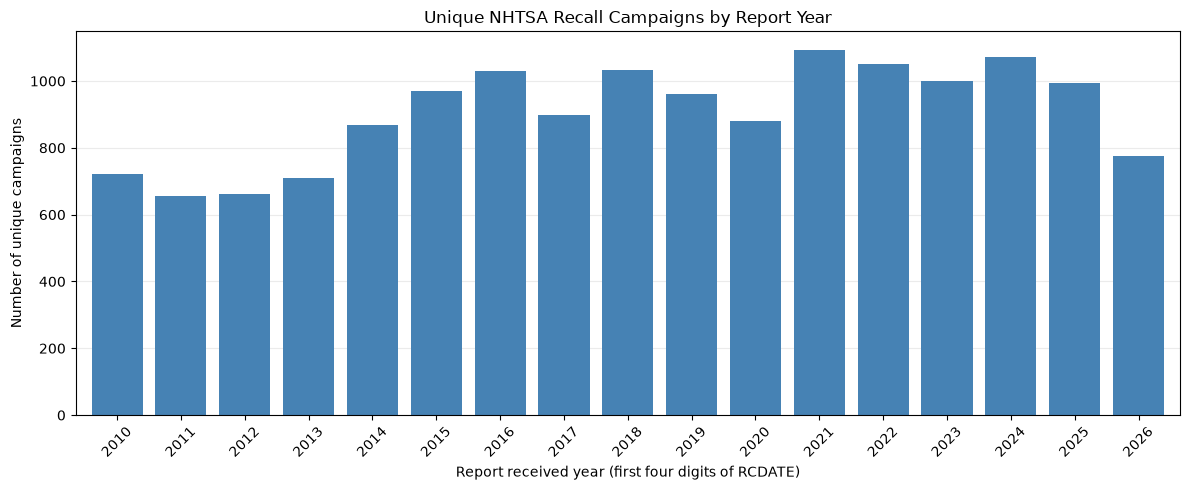

In [21]:
rcdate = recalls_df["RCDATE"].str.strip()

# Validate dates, then extract their first four digits.
valid_date = (
    rcdate.str.fullmatch(r"\d{8}", na=False)
    & pd.to_datetime(rcdate, format="%Y%m%d", errors="coerce").notna()
)
recall_year = pd.to_numeric(
    rcdate.str[:4].where(valid_date), errors="coerce"
).astype("Int64")

campaign_years = pd.DataFrame({
    "CAMPNO": campno,
    "recall_year": recall_year,
})

recalls_by_year = (
    campaign_years.dropna(subset=["CAMPNO", "recall_year"])
    .groupby("recall_year")["CAMPNO"]
    .nunique()
    .sort_index()
)

# Include any intervening years with zero campaigns.
recalls_by_year = recalls_by_year.reindex(
    range(int(recalls_by_year.index.min()), int(recalls_by_year.index.max()) + 1),
    fill_value=0,
)

print(f"Report years: {recalls_by_year.index.min()}–{recalls_by_year.index.max()}")
print(f"Rows with missing or invalid RCDATE: {(~valid_date).sum():,}")

fig, ax = plt.subplots(figsize=(12, 5))
recalls_by_year.plot.bar(ax=ax, color="steelblue", width=0.8)

ax.set(
    title="Unique NHTSA Recall Campaigns by Report Year",
    xlabel="Report received year (first four digits of RCDATE)",
    ylabel="Number of unique campaigns",
)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Since the `RCDATE` format is in `YYYYMMDD`, we can use this to our advantage and parse through to see what years are contained within our dataset. We can see that within the dataset for `FLAT_RCL_POST_2010`, no missing or invalid RCDATE values were detected (report years span 2010–2026). We also have data for the year 2026, but since the year is not over, this data is partial and would only be able to show recalls up to the point of data retrieval.

# Advisory Flags

In [22]:
for c in ["DO_NOT_DRIVE", "PARK_OUTSIDE"]:
    display(recalls_df[c].value_counts(dropna=False))

# Share flagged "Yes" by recall year
yr = recall_year
display(recalls_df["DO_NOT_DRIVE"].eq("Yes").groupby(yr).mean().round(4))

DO_NOT_DRIVE
No     245008
Yes      2141
Name: count, dtype: Int64

PARK_OUTSIDE
No     245823
Yes      1326
Name: count, dtype: Int64

RCDATE
2010       0.0
2011       0.0
2012    0.0008
2013    0.0031
2014    0.0018
2015    0.0186
2016    0.0256
2017    0.0144
2018    0.0208
2019     0.018
2020    0.0129
2021    0.0031
2022    0.0085
2023    0.0106
2024    0.0087
2025    0.0049
2026     0.011
Name: DO_NOT_DRIVE, dtype: Float64

Analysis of the `DO_NOT_DRIVE` column reveals that values were retroactively added.